In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import entropy

MOVEMENT_DIR = Path(
    r"C:\Users\Sheel\OneDrive\Documents\Default Project\data\pads-parkinsons-disease-smartwatch-dataset-1.0.0\pads-parkinsons-disease-smartwatch-dataset-1.0.0\preprocessed\movement"
)

file_list = pd.read_csv(MOVEMENT_DIR.parent / "file_list.csv")

FS = 100.0

tasks = [
    "Relaxed1", "Relaxed2", "RelaxedTask1", "RelaxedTask2",
    "StretchHold", "HoldWeight", "DrinkGlas", "CrossArms",
    "TouchNose", "Entrainment1", "Entrainment2",
]
wrists = ["LeftWrist", "RightWrist"]
sensors = ["Accelerometer", "Gyroscope"]
axes = ["X", "Y", "Z"]
channels = [f"{t}_{w}_{s}_{a}" for t in tasks for w in wrists for s in sensors for a in axes]

print(len(channels), "channels")

132 channels


In [2]:
bin_files = sorted(MOVEMENT_DIR.glob("*_ml.bin"))
ids = np.array([int(f.name.split("_")[0]) for f in bin_files])
movement = np.stack([np.fromfile(f, dtype=np.float32).reshape(len(channels), -1) for f in bin_files])
print("movement:", movement.shape, movement.dtype)

movement: (469, 132, 976) float32


In [3]:
groups = {
    "Multiple Sclerosis": [17, 36, 44, 98, 142, 195, 225, 301, 421, 432, 438],
    "Healthy Controls": [52, 193, 1, 46, 455, 254, 389, 204, 45, 108, 449],
    "Essential Tremor": [100, 200, 278, 72, 143, 104, 112, 126, 423, 124, 66],
    "Atypical Parkinsonism": [397, 64, 238, 304, 114, 291, 110, 168, 32, 15, 18],
    "Parkinson's Disease": [38, 307, 286, 299, 175, 115, 4, 119, 252, 237, 71],
}
id_to_group = {pid: g for g, pids in groups.items() for pid in pids}

mask = np.isin(ids, list(id_to_group))
mov = movement[mask]
pids = ids[mask]

channel_df = pd.DataFrame({
    "channel": channels,
    "task": [c.split("_")[0] for c in channels],
    "wrist": [c.split("_")[1] for c in channels],
    "sensor": [c.split("_")[2] for c in channels],
    "axis": [c.split("_")[3] for c in channels],
})


def stream_predictors(acc_norm):
    eps = 1e-12
    n = acc_norm.shape[1]
    freqs = np.fft.rfftfreq(n, d=1 / FS)
    power = np.abs(np.fft.rfft(acc_norm, axis=1)) ** 2

    primary_freq = freqs[1:][np.argmax(power[:, 1:], axis=1)]
    spec_entropy = entropy(power[:, 1:] + eps, axis=1)
    jerk = np.diff(acc_norm, axis=1)

    # Velocity proxy from IMU acceleration magnitude.
    velocity = np.cumsum(acc_norm - acc_norm.mean(axis=1, keepdims=True), axis=1) / FS
    mean_velocity = np.mean(np.abs(velocity), axis=1)

    tremor_band = (freqs >= 4.0) & (freqs <= 8.0)
    total_power = power[:, 1:].sum(axis=1) + eps
    tremor_power = power[:, tremor_band].sum(axis=1)
    relative_tremor_power = tremor_power / total_power

    if tremor_band.any():
        tremor_power_matrix = power[:, tremor_band]
        main_idx = np.argmax(tremor_power_matrix, axis=1)
        main_freqs = freqs[tremor_band][main_idx]
        main_power = tremor_power_matrix[np.arange(power.shape[0]), main_idx] + eps

        harmonic_power = np.zeros(power.shape[0], dtype=np.float64)
        for harmonic in (2.0, 3.0):
            target_freq = main_freqs * harmonic
            nearest_idx = np.abs(freqs[None, :] - target_freq[:, None]).argmin(axis=1)
            harmonic_power += power[np.arange(power.shape[0]), nearest_idx]
        harmonic_power_ratio = harmonic_power / main_power
    else:
        harmonic_power_ratio = np.zeros(power.shape[0], dtype=np.float64)

    movement_amplitude = np.ptp(acc_norm, axis=1)

    return {
        "Primary Frequency Component": primary_freq,
        "Acceleration Norm": acc_norm.mean(axis=1),
        "Jerk": jerk.mean(axis=1),
        "Signal Change Variability": jerk.std(axis=1),
        "Spectral Entropy": spec_entropy,
        "Mean Velocity": mean_velocity,
        "Relative Tremor Power": relative_tremor_power,
        "Harmonic Power Ratio": harmonic_power_ratio,
        "Movement Amplitude": movement_amplitude,
    }


pred_names = [
    "Primary Frequency Component",
    "Acceleration Norm",
    "Jerk",
    "Signal Change Variability",
    "Spectral Entropy",
    "Mean Velocity",
    "Relative Tremor Power",
    "Harmonic Power Ratio",
    "Movement Amplitude",
]
preds = {k: [] for k in pred_names}

for (task, wrist), grp in channel_df.groupby(["task", "wrist"]):
    acc = mov[:, grp.index[grp["sensor"] == "Accelerometer"].tolist(), :]
    acc_norm = np.linalg.norm(acc, axis=1)
    for k, v in stream_predictors(acc_norm).items():
        preds[k].append(v)

df = pd.DataFrame({k: np.mean(v, axis=0) for k, v in preds.items()})
df["group"] = [id_to_group[p] for p in pids]
print(df.shape)
print(df.groupby("group").size())

(55, 10)
group
Atypical Parkinsonism    11
Essential Tremor         11
Healthy Controls         11
Multiple Sclerosis       11
Parkinson's Disease      11
dtype: int64


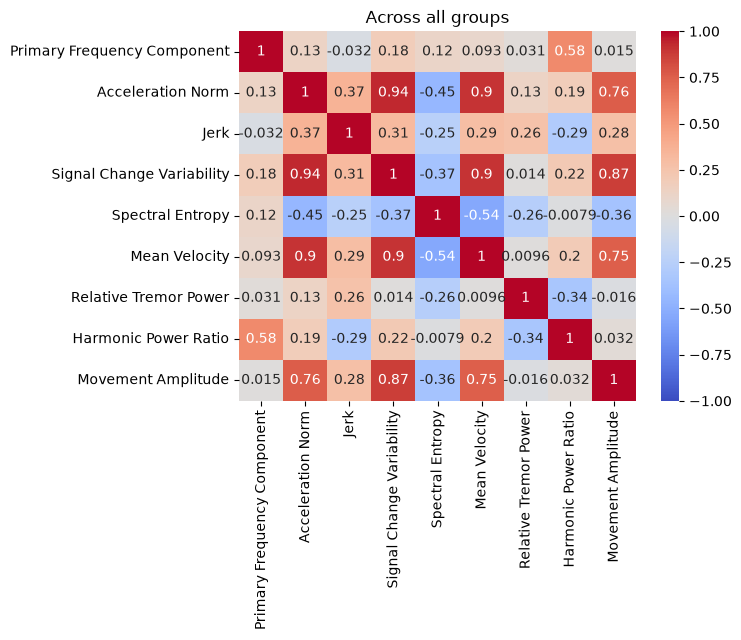

In [4]:
sns.heatmap(df.drop(columns=["group"]).corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Across all groups")
plt.show()

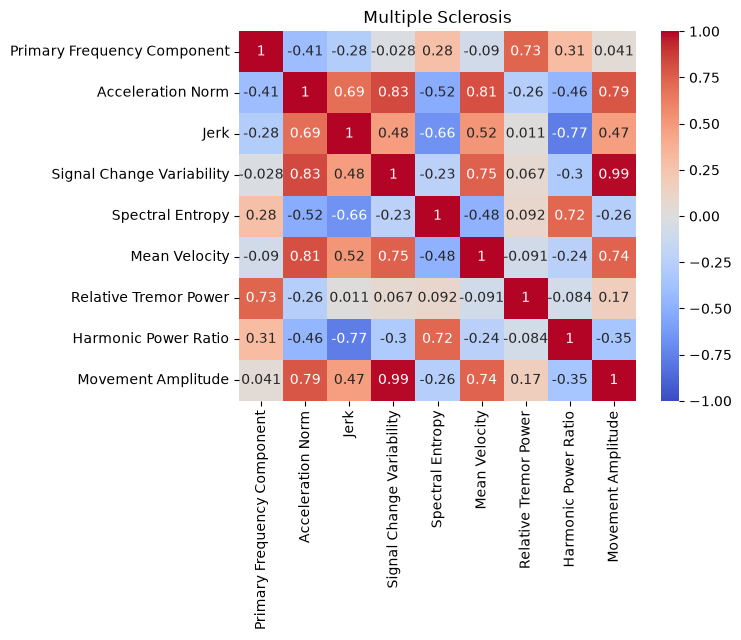

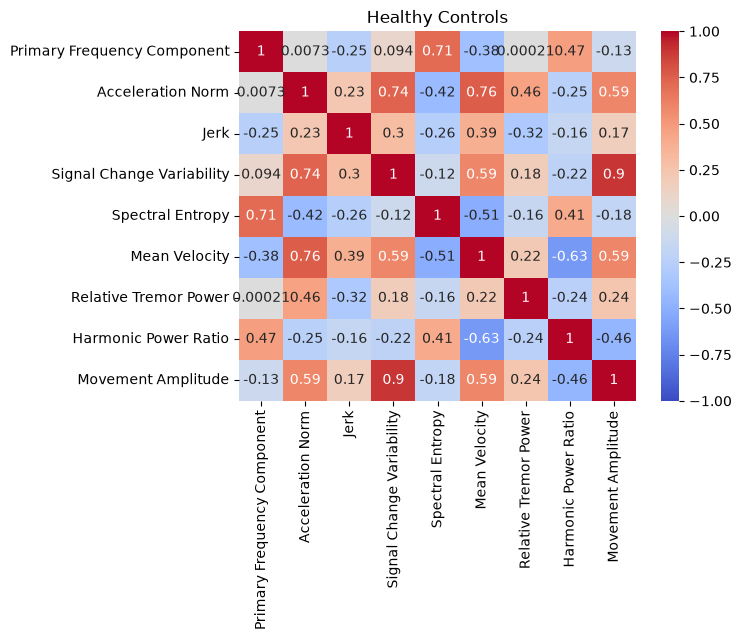

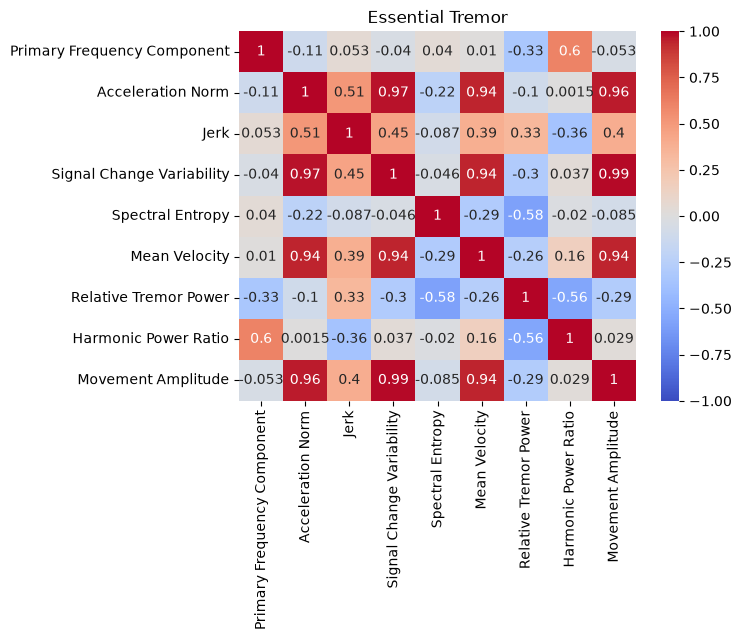

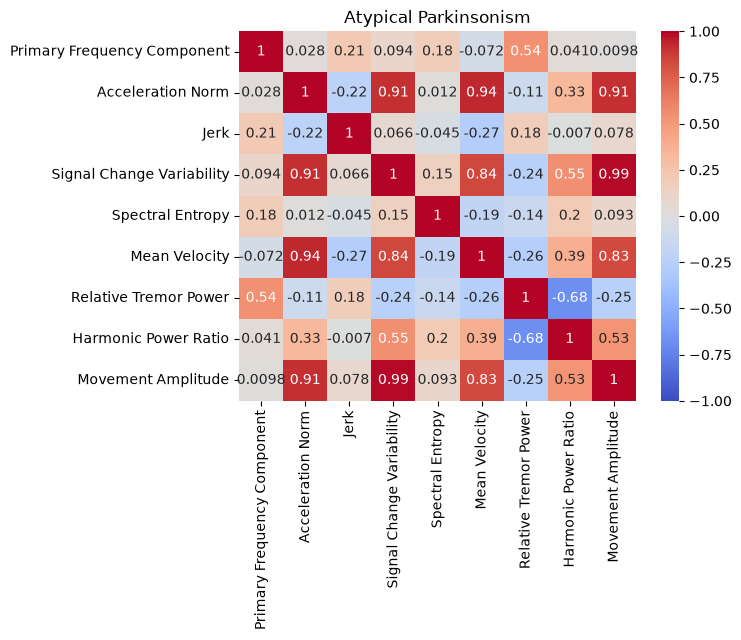

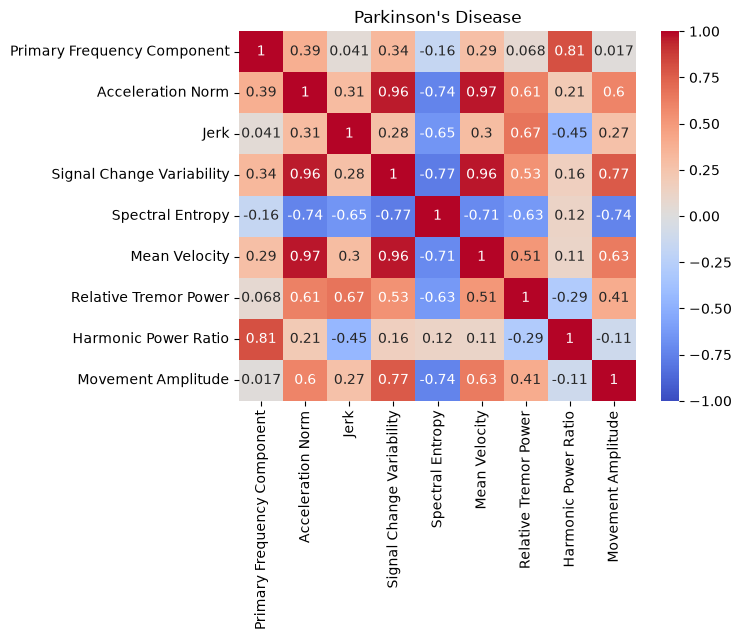

In [5]:
for g in groups:
    sub = df[df["group"] == g].drop(columns=["group"])
    sns.heatmap(sub.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
    plt.title(g)
    plt.show()